# Hafta 4 · Katsayılara Ceza Kesmek

**Ekonomi ve Finansta Makine Öğrenmesi** · Prof. Dr. Mehmet Songur · Dicle Üniversitesi

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mehmetsongur/Machine-Learning-in-Economics-and-Finance/blob/main/code/Hafta04_Ridge_ve_Lasso.ipynb)

**Haftanın konusu:** Regresyon ve düzenlileştirme: EKK, Ridge, Lasso

Bu defter, Hafta 4 ders notundaki ve slaytlarındaki şu şekil ve tabloları üretir:

- **Şekil 1 (2.3):** Ridge ve Lasso’nun geometrisi: daire, baklava dilimi ve köşe çözümü
- **Tablo (1.3):** 40 değişkenli ücret denkleminde EKK, Ridge ve Lasso (200 tekrar)
- **Seçim oranları (4.2):** Lasso gerçek değişkenleri ne sıklıkla seçiyor?
- **Şekil 2–5:** Ridge ve Lasso katsayı yolları, üç yöntemin katsayıları, λ için çapraz doğrulama eğrisi
- **Şekil 6 (6.2):** Gözlem sayısı arttıkça üç yöntemin test hatası
- **Tablo (4.3):** Benzer iki değişkenden (deneyim ve yaş) hangisi seçiliyor?

Tüm sayılar yapay (simüle edilmiş) veriye dayanır. Rastgele sayı üreticisinin tohumu sabit olduğu için hücreler **yukarıdan aşağıya sırayla** çalıştırıldığında sonuçlar ders materyalindeki değerlerle birebir aynı çıkar. Hücreleri atlarsanız ya da sırasını değiştirirseniz sayılar biraz farklılaşabilir; yorumlar değişmez.

Slaytlar: [Hafta 4 (PDF)](https://www.songurmehmet.com/assets/dersler/ml/Hafta04_Slaytlar.pdf)  
Kod MIT lisansıyla paylaşılmıştır; ayrıntı için deponun `code/LICENSE` dosyasına bakın.

## Kurulum

Hafta 3’teki ücret dünyasını genişletiyoruz. Gerçek modelde log ücreti yalnızca **beş** değişken belirliyor: eğitim, deneyim, deneyim², kıdem ve büyükşehirde yaşamak. Veri setinde bunlara ek olarak **35 alakasız değişken** var: deneyimle çok yüksek korelasyonlu (ρ ≈ 0,97) “yaş” ve gerçek değişkenlerle kısmen ilişkili 34 anket sorusu. Tüm değişkenler standart normal ölçekte.

**Süre uyarısı:** Tekrar sayısı yüksek olduğu için defterin tamamı Colab’da birkaç dakika sürebilir. Derste canlı göstermek için `HIZLI = True` yapın; o zaman tekrar sayıları düşer ve sayılar ders notundakilerden biraz farklı çıkar, ama sonuçların yönü aynı kalır.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

HIZLI = False                     # True: derste hızlı gösterim (sayılar ders notundan biraz farklı çıkar)
R_ANA, R_N = (40, 15) if HIZLI else (200, 60)   # ana deney ve 'gözlem sayısı' deneyi için tekrar sayıları

rng = np.random.default_rng(2026)  # tohum: tam modda sonuçlar ders notuyla aynı çıkar
P, SIG = 40, 0.30                  # değişken sayısı; gürültünün standart sapması → indirgenemez hata = 0,09
adlar = ['Eğitim', 'Deneyim', 'Deneyim²', 'Kıdem', 'Büyükşehir', 'Yaş'] + [f'Anket {i}' for i in range(1, 35)]
beta = np.zeros(P); beta[:5] = [0.30, 0.25, -0.12, 0.10, 0.12]    # yalnızca ilk beş değişkenin etkisi var

def ciz(n, rho=0.97, g=None):
    g = rng if g is None else g
    Z = g.normal(size=(n, P)); X = Z.copy()
    X[:, 5] = rho * X[:, 1] + np.sqrt(1 - rho**2) * Z[:, 5]          # yaş ≈ deneyim
    for j in range(6, P):                                              # anket soruları gerçek değişkenlerle kısmen ilişkili
        X[:, j] = 0.5 * X[:, j % 5] + np.sqrt(0.75) * Z[:, j]
    return X, 2.5 + X @ beta + g.normal(0, SIG, n)

hko = lambda a, b: float(np.mean((a - b) ** 2))
LASSO_IZGARA = np.logspace(-3.5, 0.5, 60)
KATLAR = KFold(5, shuffle=True, random_state=1)

def uc_model(X, y):
    '''Değişkenleri eğitim verisinden standartlaştır; EKK, Ridge ve Lasso kur (λ 5-katlı çapraz doğrulamayla).'''
    sc = StandardScaler().fit(X); Xs = sc.transform(X)
    ekk = LinearRegression().fit(Xs, y)
    ridge = RidgeCV(alphas=np.logspace(-2, 4, 60), cv=KATLAR).fit(Xs, y)
    lasso = LassoCV(alphas=LASSO_IZGARA, cv=KATLAR, max_iter=20000).fit(Xs, y)
    return sc, ekk, ridge, lasso

## 1. Ridge ve Lasso’nun geometrisi (Şekil 1)

İki katsayılı bir model. Gri elipsler eşit hata eğrileri (kayıtsızlık eğrileri gibi; merkezde EKK çözümü), renkli bölge katsayı “bütçesi”. Çözümü kaba kuvvetle buluyoruz: kısıt bölgesinin sınırındaki binlerce nokta arasından hatası en küçük olanı seçiyoruz. Ridge’de çözüm bir iç noktada, Lasso’da ise köşede: β₂ = 0. Bu, tüketici teorisindeki **köşe çözümüdür**.

Ridge: β₁² + β₂² ≤ 1     çözüm: β₁ = 0.88, β₂ = 0.48
Lasso: |β₁| + |β₂| ≤ 1   çözüm: β₁ = 1.00, β₂ = 0.00


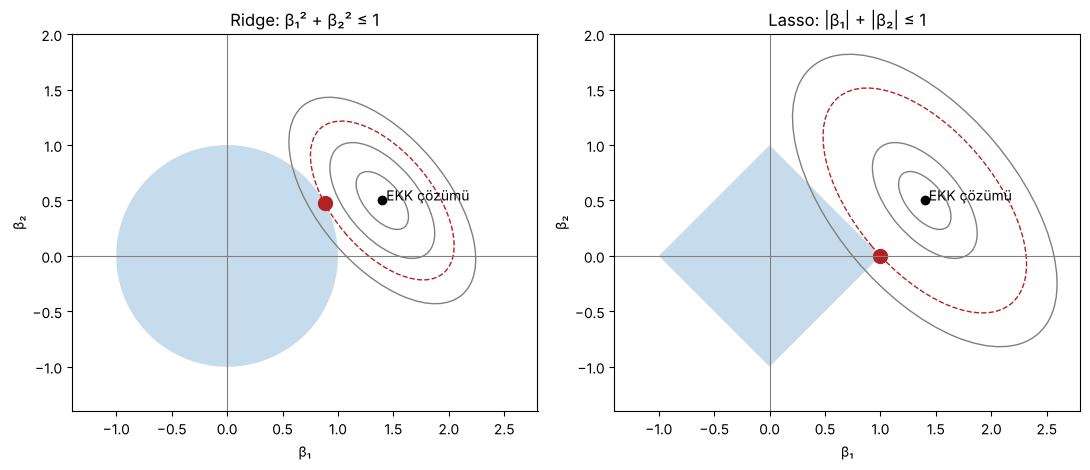

In [2]:
from matplotlib.patches import Ellipse, Circle, Polygon
merkez = np.array([1.4, 0.5]); aci = -50; eksen = np.array([1.25, 0.65])
th = np.deg2rad(aci); Rm = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
def hata(P_): return np.sqrt((((P_ - merkez) @ Rm / eksen) ** 2).sum(axis=1))    # elips 'yüksekliği'

t = np.linspace(0, 2 * np.pi, 6000); birim = np.c_[np.cos(t), np.sin(t)]
sinirlar = {'Ridge: β₁² + β₂² ≤ 1': birim, 'Lasso: |β₁| + |β₂| ≤ 1': birim / np.abs(birim).sum(axis=1, keepdims=True)}

fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (baslik, S) in zip(axs, sinirlar.items()):
    h = hata(S); cozum = S[np.argmin(h)]; seviye = h.min()
    print(f'{baslik:24s} çözüm: β₁ = {cozum[0]:.2f}, β₂ = {cozum[1]:.2f}')
    ax.fill(S[:, 0], S[:, 1], alpha=0.25)
    for s in [0.25, 0.5, seviye, seviye * 1.3]:
        ax.add_patch(Ellipse(merkez, 2 * s * eksen[0], 2 * s * eksen[1], angle=aci, fill=False,
                             ec='firebrick' if s == seviye else 'grey', ls='--' if s == seviye else '-'))
    ax.plot(*merkez, 'ko'); ax.annotate(' EKK çözümü', merkez)
    ax.plot(*cozum, 'o', color='firebrick', ms=10)
    ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
    ax.set(title=baslik, xlabel='β₁', ylabel='β₂', xlim=(-1.4, 2.8), ylim=(-1.4, 2.0)); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

## 2. Ana deney: 100 kişi, 40 değişken (tablo 1.3 ve seçim oranları 4.2)

Her tekrarda 100 kişilik bir eğitim örneklemi çekip üç modeli kuruyor, 5.000 yeni kişide test ediyoruz. Lasso’nun hangi değişkenleri seçtiğini de kaydediyoruz. (Tam modda bu hücre en uzun süren hücredir.)

In [3]:
X_tst, y_tst = ciz(5000)
sonuc = {k: [] for k in ['ekk', 'ridge', 'lasso', 'ekk_egt', 'ridge_egt', 'lasso_egt']}
secilen_sayisi, gercek_secim, alakasiz_secim = [], np.zeros(5), []

for r in range(R_ANA):
    X, y = ciz(100)
    sc, ekk, ridge, lasso = uc_model(X, y)
    Xs, Xts = sc.transform(X), sc.transform(X_tst)
    for ad, m in [('ekk', ekk), ('ridge', ridge), ('lasso', lasso)]:
        sonuc[ad].append(hko(m.predict(Xts), y_tst)); sonuc[ad + '_egt'].append(hko(m.predict(Xs), y))
    sifirdan_farkli = np.abs(lasso.coef_) > 1e-8
    secilen_sayisi.append(sifirdan_farkli.sum()); gercek_secim += sifirdan_farkli[:5]; alakasiz_secim.append(sifirdan_farkli[5:].sum())

print('Model    ortalama eğitim hatası   ortalama test hatası')
for ad, etiket in [('ekk', 'EKK'), ('ridge', 'Ridge'), ('lasso', 'Lasso')]:
    print(f'{etiket:7s}  {np.mean(sonuc[ad + "_egt"]):22.3f}   {np.mean(sonuc[ad]):20.3f}')
print(f'İndirgenemez hata: {SIG**2:.3f}\n')
print(f'Lasso ortalama {np.mean(secilen_sayisi):.1f} değişken seçti; her seferinde ortalama {np.mean(alakasiz_secim):.1f} alakasız değişken de modele girdi.')
for ad, oran in zip(adlar[:5], 100 * gercek_secim / R_ANA):
    print(f'  {ad:11s} seçilme oranı: %{oran:.0f}')

Model    ortalama eğitim hatası   ortalama test hatası
EKK                       0.053                  0.156
Ridge                     0.072                  0.130
Lasso                     0.075                  0.113
İndirgenemez hata: 0.090

Lasso ortalama 15.9 değişken seçti; her seferinde ortalama 11.3 alakasız değişken de modele girdi.
  Eğitim      seçilme oranı: %100
  Deneyim     seçilme oranı: %96
  Deneyim²    seçilme oranı: %91
  Kıdem       seçilme oranı: %87
  Büyükşehir  seçilme oranı: %95


Beklenen (tam mod): test hatası EKK 0,156, Ridge 0,130, Lasso 0,113. Lasso ortalama 15,9 değişken seçiyor; gerçek beşin seçilme oranları %100, %96, %91, %87, %95; ama her seferinde ortalama 11,3 alakasız değişken de giriyor. Lasso mükemmel bir değişken seçici değildir: λ öngörü hatasını en küçük yapmak için seçilir.

## 3. Tek bir örneklemde katsayılar ve yollar (Şekil 2–5)

Lasso’nun sıfırdan farklı katsayı sayısı: 8 / 40


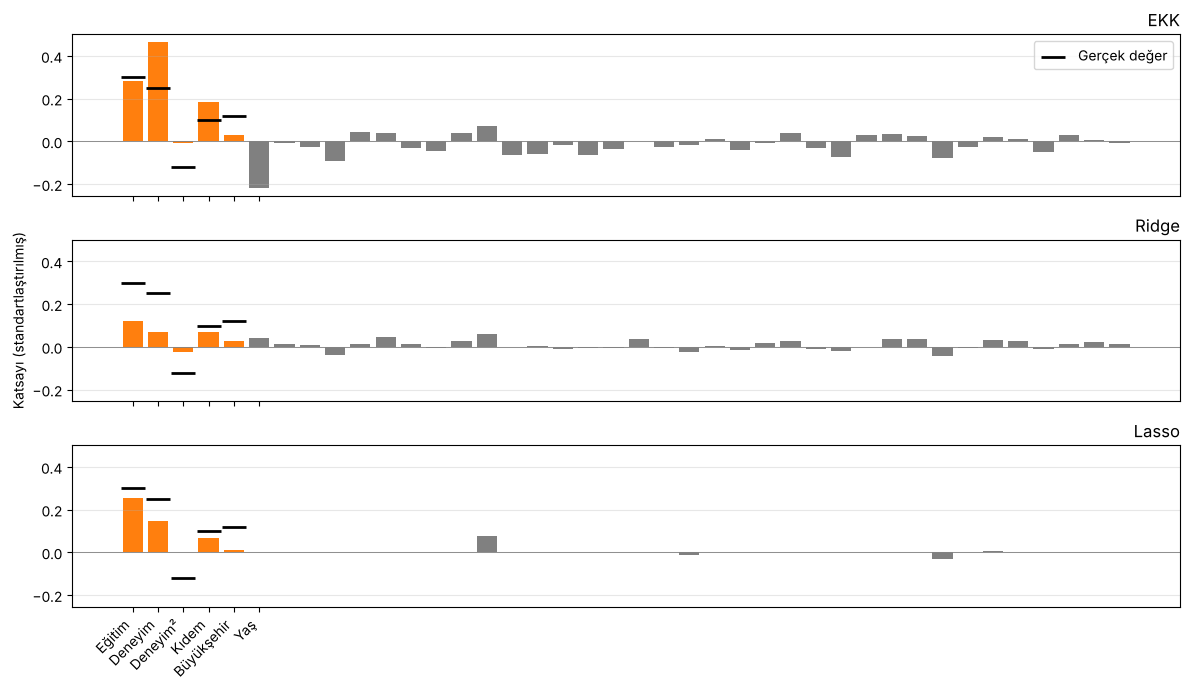

In [4]:
X, y = ciz(100)
sc, ekk, ridge, lasso = uc_model(X, y); Xs = sc.transform(X)
print('Lasso’nun sıfırdan farklı katsayı sayısı:', int((np.abs(lasso.coef_) > 1e-8).sum()), '/ 40')

# Şekil 4: üç yöntemin katsayıları
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, (ad, m) in zip(axs, [('EKK', ekk), ('Ridge', ridge), ('Lasso', lasso)]):
    ax.bar(range(P), m.coef_, color=['C1' if j < 5 else 'grey' for j in range(P)])
    ax.scatter(range(5), beta[:5], marker='_', s=300, color='k', lw=2, zorder=5, label='Gerçek değer')
    ax.axhline(0, color='grey', lw=0.6); ax.set_title(ad, loc='right'); ax.grid(axis='y', alpha=0.3)
axs[0].legend(); axs[1].set_ylabel('Katsayı (standartlaştırılmış)')
axs[2].set_xticks(range(6)); axs[2].set_xticklabels(adlar[:6], rotation=45, ha='right')
plt.tight_layout(); plt.show()

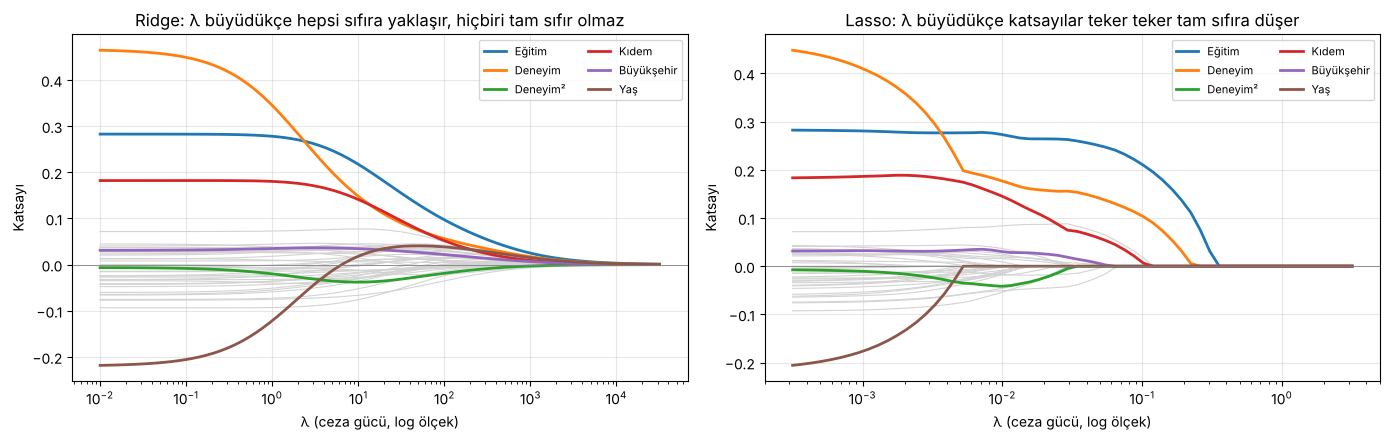

In [5]:
# Şekil 2 ve 3: katsayı yolları (renkli: 5 gerçek etken ve yaş; gri: 34 anket sorusu)
ridge_izgara = np.logspace(-2, 4.5, 80)
yollar = {'Ridge: λ büyüdükçe hepsi sıfıra yaklaşır, hiçbiri tam sıfır olmaz': (ridge_izgara, np.array([Ridge(alpha=a).fit(Xs, y).coef_ for a in ridge_izgara])),
          'Lasso: λ büyüdükçe katsayılar teker teker tam sıfıra düşer': (LASSO_IZGARA, np.array([Lasso(alpha=a, max_iter=20000).fit(Xs, y).coef_ for a in LASSO_IZGARA]))}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (baslik, (lam, yol)) in zip(axs, yollar.items()):
    for j in range(6, P): ax.plot(lam, yol[:, j], color='lightgrey', lw=0.8)
    for j in range(6):    ax.plot(lam, yol[:, j], lw=2, label=adlar[j])
    ax.set(xscale='log', title=baslik, xlabel='λ (ceza gücü, log ölçek)', ylabel='Katsayı'); ax.axhline(0, color='grey', lw=0.6)
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

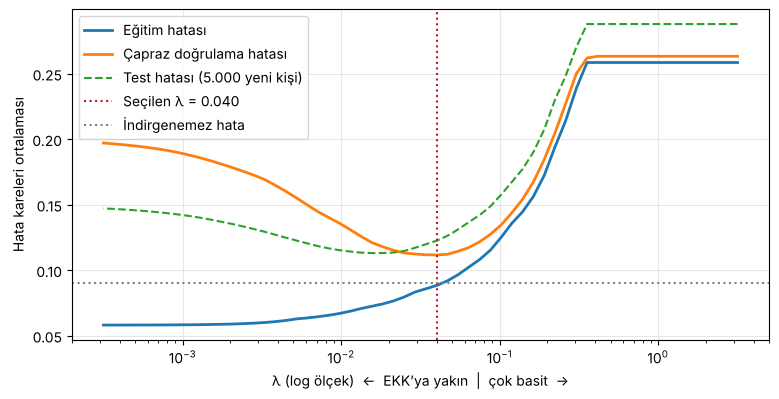

In [6]:
# Şekil 5: λ için çapraz doğrulama eğrisi
lam = lasso.alphas_
cv_hatasi = lasso.mse_path_.mean(axis=1)
egt_hatasi = [hko(Lasso(alpha=a, max_iter=20000).fit(Xs, y).predict(Xs), y) for a in lam]
tst_hatasi = [hko(Lasso(alpha=a, max_iter=20000).fit(Xs, y).predict(sc.transform(X_tst)), y_tst) for a in lam]
plt.figure(figsize=(9, 4.3))
plt.plot(lam, egt_hatasi, lw=2, label='Eğitim hatası')
plt.plot(lam, cv_hatasi, lw=2, label='Çapraz doğrulama hatası')
plt.plot(lam, tst_hatasi, '--', label='Test hatası (5.000 yeni kişi)')
plt.axvline(lasso.alpha_, color='firebrick', ls=':', label=f'Seçilen λ = {lasso.alpha_:.3f}')
plt.axhline(SIG**2, color='grey', ls=':', label='İndirgenemez hata')
plt.xscale('log'); plt.xlabel('λ (log ölçek)  ←  EKK’ya yakın  |  çok basit  →'); plt.ylabel('Hata kareleri ortalaması')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Kazanç ne zaman büyüktür? (Şekil 6)

Aynı dünyada gözlem sayısını değiştiriyoruz (40 değişken).

n =    60   EKK 0.296   Ridge 0.147   Lasso 0.133


n =   100   EKK 0.152   Ridge 0.128   Lasso 0.111


n =   200   EKK 0.115   Ridge 0.113   Lasso 0.102


n =  1000   EKK 0.095   Ridge 0.095   Lasso 0.093


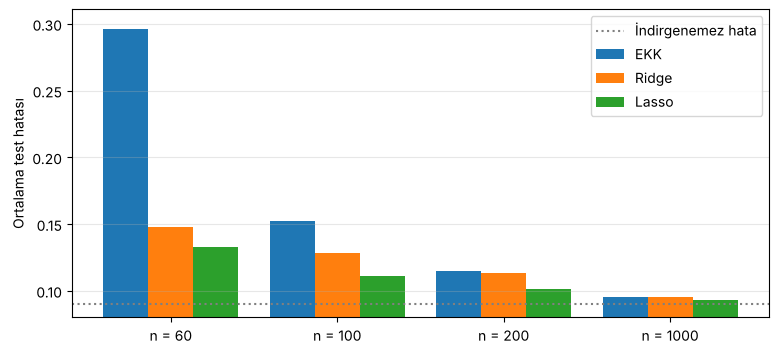

In [7]:
ns = [60, 100, 200, 1000]; buyume = {}
for n in ns:
    hatalar = {'EKK': [], 'Ridge': [], 'Lasso': []}
    for r in range(R_N):
        Xn, yn = ciz(n); s2, e2, r2, l2 = uc_model(Xn, yn); Xts = s2.transform(X_tst)
        for ad, m in [('EKK', e2), ('Ridge', r2), ('Lasso', l2)]: hatalar[ad].append(hko(m.predict(Xts), y_tst))
    buyume[n] = {k: np.mean(v) for k, v in hatalar.items()}
    print(f'n = {n:5d}   ' + '   '.join(f'{k} {v:.3f}' for k, v in buyume[n].items()))

x = np.arange(len(ns)); w = 0.27
plt.figure(figsize=(9, 4))
for i, ad in enumerate(['EKK', 'Ridge', 'Lasso']):
    plt.bar(x + (i - 1) * w, [buyume[n][ad] for n in ns], w, label=ad)
plt.axhline(SIG**2, color='grey', ls=':', label='İndirgenemez hata')
plt.xticks(x, [f'n = {n}' for n in ns]); plt.ylim(0.08, None); plt.ylabel('Ortalama test hatası'); plt.legend(); plt.grid(axis='y', alpha=0.3); plt.show()

Beklenen (tam mod): 60 gözlemde EKK 0,296, Lasso 0,133; 1.000 gözlemde EKK 0,095, Lasso 0,093. Düzenlileştirme “az veri, çok değişken” durumunun ilacıdır; bol veride EKK ile fark kalmaz.

## 5. Benzer iki değişken: Lasso hangisini seçer? (tablo 4.3)

Deneyim ile yaş arasındaki korelasyonu 0,97 ve 0,995 alarak her biri için deneyi tekrarlıyoruz. Bu bölüm ayrı bir rastgele sayı üreticisi kullanır.

In [8]:
rng_b = np.random.default_rng(7)
R_B = 40 if HIZLI else 150
for rho in [0.97, 0.995]:
    say = {'yalnızca deneyim': 0, 'yalnızca yaş': 0, 'ikisi birden': 0, 'hiçbiri': 0}
    for r in range(R_B):
        X, y = ciz(100, rho=rho, g=rng_b)
        m = LassoCV(alphas=LASSO_IZGARA, cv=KATLAR, max_iter=20000).fit(StandardScaler().fit_transform(X), y)
        d, a = abs(m.coef_[1]) > 1e-8, abs(m.coef_[5]) > 1e-8
        say['ikisi birden' if d and a else 'yalnızca deneyim' if d else 'yalnızca yaş' if a else 'hiçbiri'] += 1
    print(f'korelasyon {rho}: ' + ', '.join(f'{k} %{100 * v / R_B:.0f}' for k, v in say.items()))

korelasyon 0.97: yalnızca deneyim %59, yalnızca yaş %7, ikisi birden %35, hiçbiri %0


korelasyon 0.995: yalnızca deneyim %50, yalnızca yaş %23, ikisi birden %27, hiçbiri %0


Beklenen (tam mod): 0,97’de yalnızca deneyim %59, yalnızca yaş %7, ikisi birden %35; 0,995’te sırasıyla %50, %23, %27. İki değişken arasında küçük bir fark varken Lasso çoğunlukla gerçek değişkeni buluyor; değişkenler neredeyse aynılaştıkça seçim istikrarsızlaşıyor. **Lasso’nun bir değişkeni seçmemesi, o değişkenin önemsiz olduğu anlamına gelmez.**